# Data Analysis, Data Preprocessing, Feature Engineering on Video Game Sales Dataset

In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load the Dataset

In [2]:
df = pd.read_csv('vgsales.csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


## Dataset Description
- **Rank** – Ranking of the game based on global sales
- **Name** – Name of the video game
- **Platform** – Platform the game was released on (e.g., PS4, X360)
- **Year** – Release year of the game
- **Genre** – Type of game (e.g., Action, Sports)
- **Publisher** – Company that published the game
- **NA_Sales** – Sales in North America (in millions)
- **EU_Sales** – Sales in Europe (in millions)
- **JP_Sales** – Sales in Japan (in millions)
- **Other_Sales** – Sales in other regions (in millions)
- **Global_Sales** – Total worldwide sales (in millions)

## Basic Data Exploration

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16291 entries, 0 to 16290
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  object 
 2   Platform      16291 non-null  object 
 3   Year          16291 non-null  float64
 4   Genre         16291 non-null  object 
 5   Publisher     16291 non-null  object 
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB


In [4]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
mean,8290.190228,2006.405561,0.265647,0.147731,0.078833,0.048426,0.540910
std,4792.654450,5.832412,0.822432,0.509303,0.311879,0.190083,1.567345
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4132.500000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8292.000000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12439.500000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.480000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [5]:
df.shape

(16291, 11)

## Data Visualization — Comparing Features with Target Variable

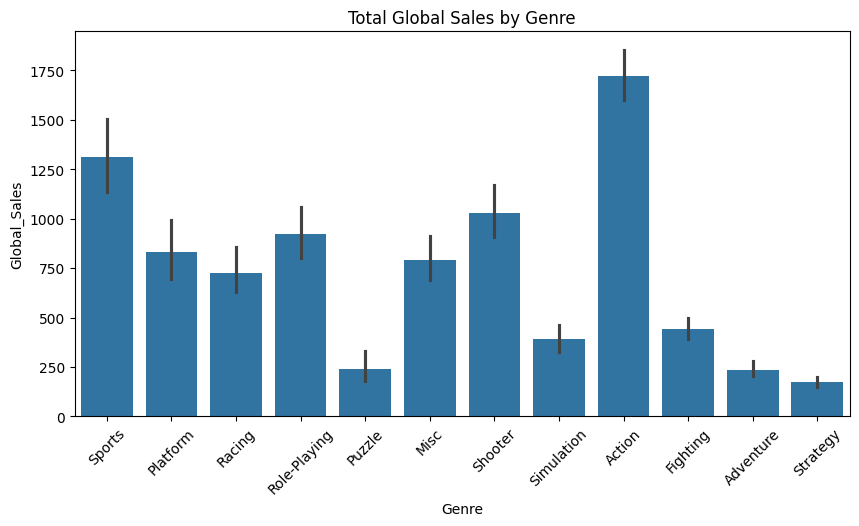

In [6]:
plt.figure(figsize=(10,5))
sns.barplot(x='Genre', y='Global_Sales', data=df, estimator=sum)
plt.title('Total Global Sales by Genre')
plt.xticks(rotation=45)
plt.show()

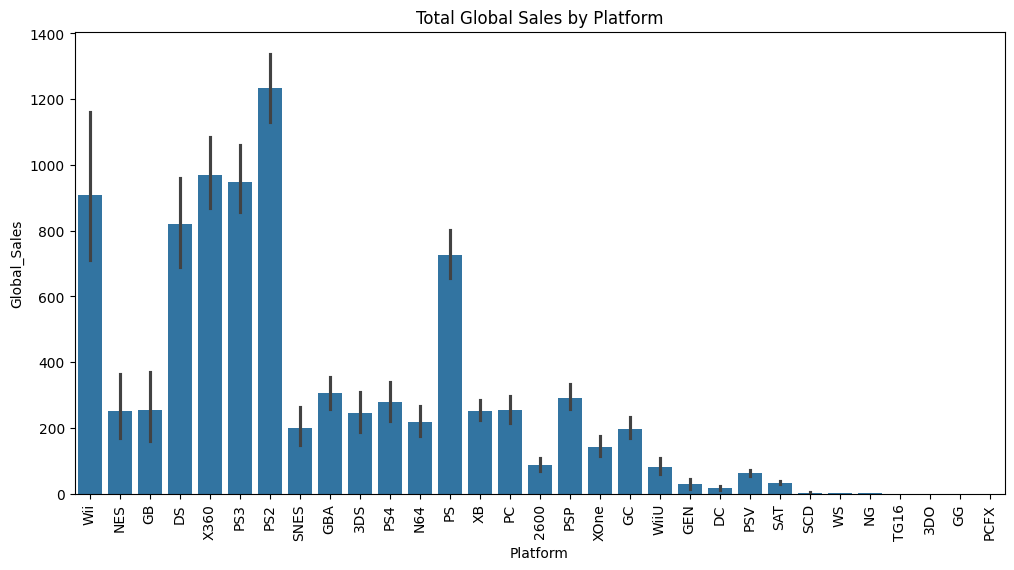

In [7]:
plt.figure(figsize=(12,6))
sns.barplot(x='Platform', y='Global_Sales', data=df, estimator=sum)
plt.title('Total Global Sales by Platform')
plt.xticks(rotation=90)
plt.show()

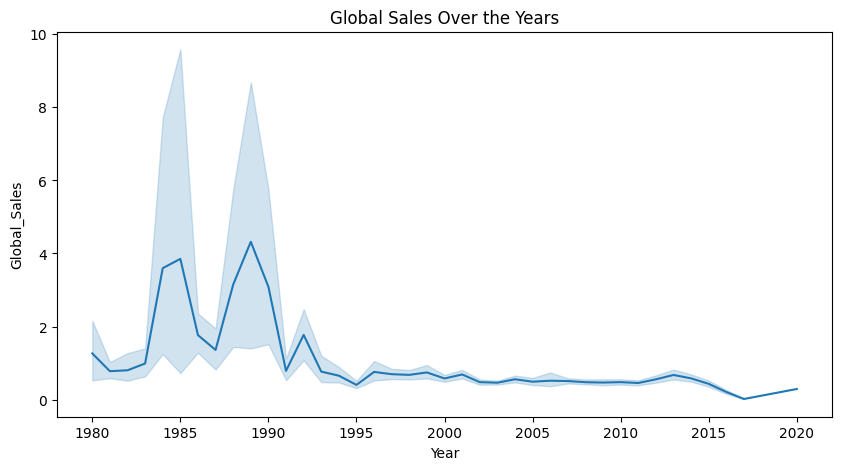

In [8]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Year', y='Global_Sales', data=df)
plt.title('Global Sales Over the Years')
plt.show()

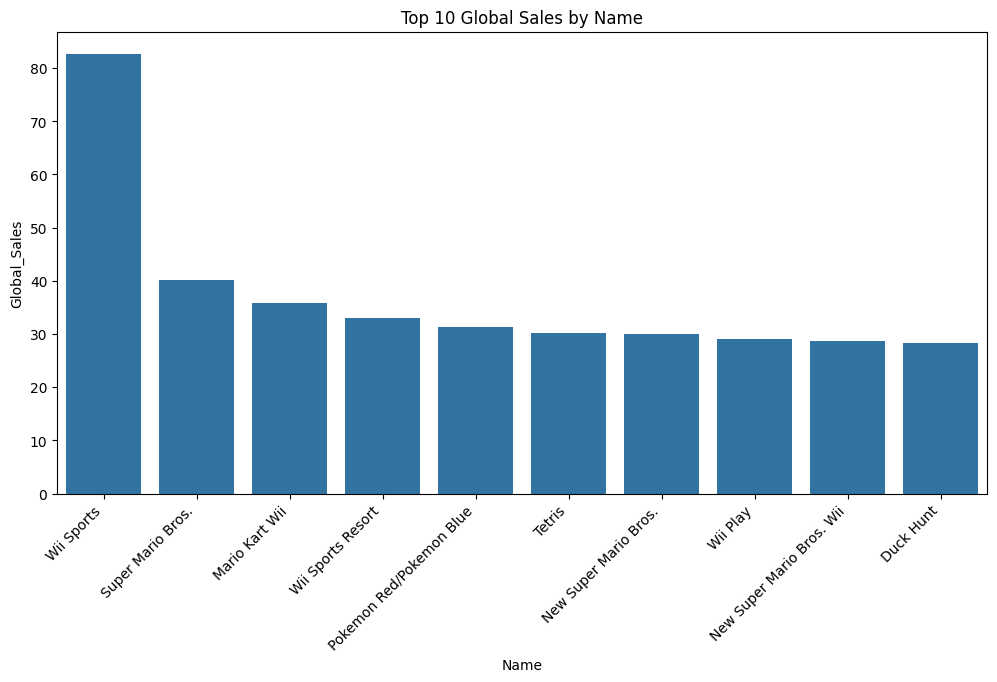

In [9]:
plt.figure(figsize=(12,6))
sns.barplot(x='Name', y='Global_Sales', data=df.sort_values('Global_Sales', ascending=False).head(10))
plt.xticks(rotation=45, ha='right')
plt.title('Top 10 Global Sales by Name')
plt.show()


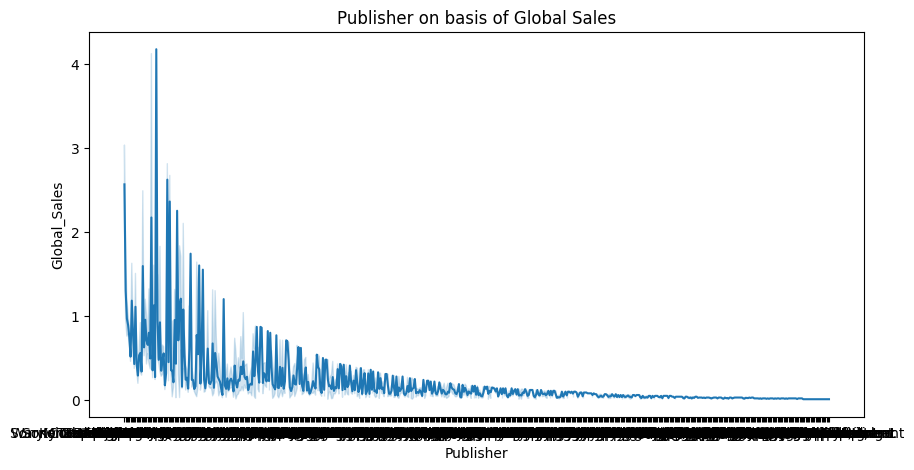

In [10]:
plt.figure(figsize=(10,5))
sns.lineplot(x='Publisher', y='Global_Sales', data=df)
plt.title('Publisher on basis of Global Sales')
plt.show()

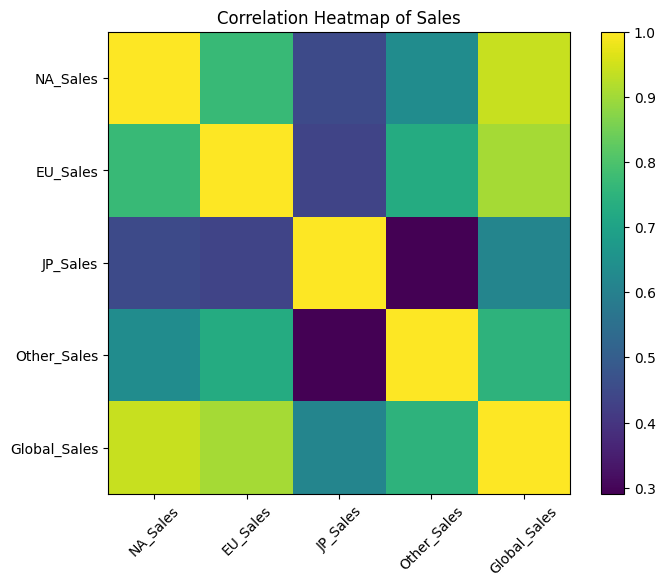

In [11]:
plt.figure(figsize=(8,6))
corr = df[['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales']].corr()
plt.imshow(corr, cmap='viridis')
plt.xticks(range(len(corr.columns)), corr.columns, rotation=45)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.colorbar()
plt.title('Correlation Heatmap of Sales')
plt.show()
plt.close()

In [12]:
pip install wordcloud


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


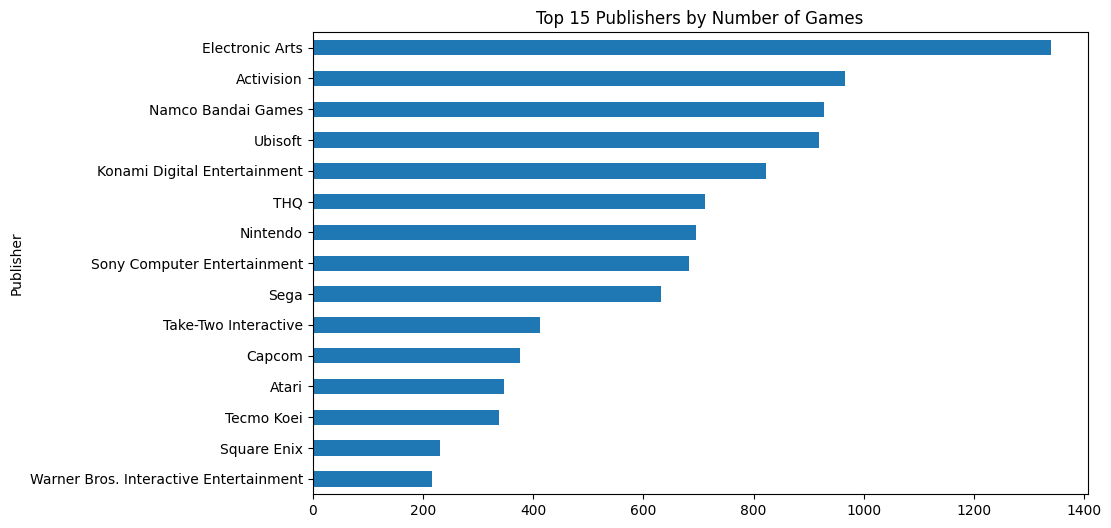

In [15]:
df['Publisher'].value_counts().head(15).plot(kind='barh', figsize=(10,6))
plt.title("Top 15 Publishers by Number of Games")
plt.gca().invert_yaxis()
plt.show()

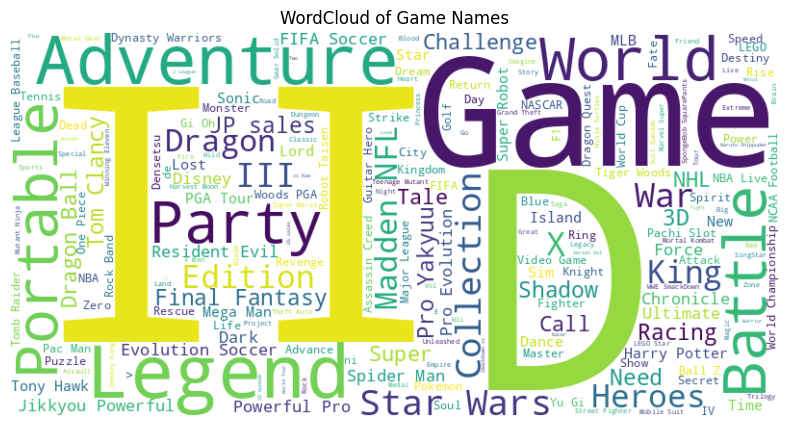

In [ ]:
from wordcloud import WordCloud

text = ' '.join(df['Name'].dropna().astype(str).tolist())
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title("WordCloud of Game Names")
plt.show()


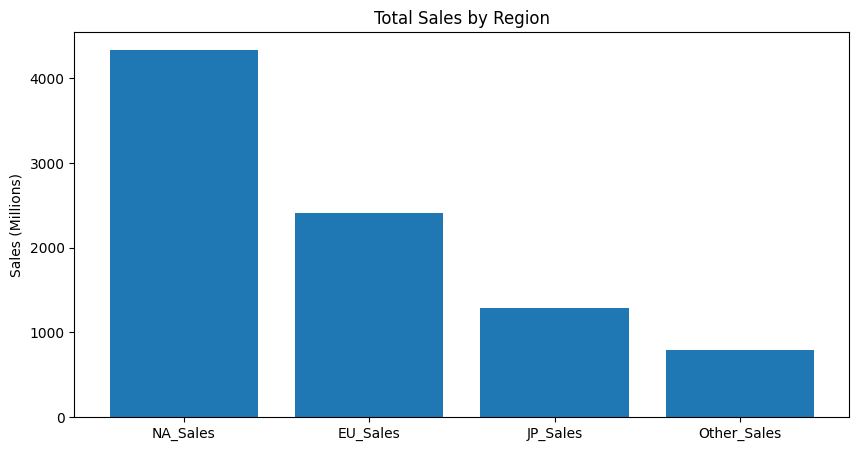

In [ ]:
plt.figure(figsize=(10,5))
regions = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
region_totals = df[regions].sum()
plt.bar(region_totals.index, region_totals.values)
plt.title('Total Sales by Region')
plt.ylabel('Sales (Millions)')
plt.show()
plt.close()

## Observations
- **Action** and **Sports** genres have the highest total global sales.
- **PS2** and **X360** are among the top-performing platforms.
- Sales peaked around **2008–2009** and then declined over time.

## Data Preprocessing

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load Dataset

In [17]:
df = pd.read_csv("vgsales.csv")
df.head(16599)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16286,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16287,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16288,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16289,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


## check for null values
### Remove na values 

In [18]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [19]:
df["Year"] = df["Year"].fillna(df["Year"].median())

In [20]:
df.dropna(subset=["Year"], inplace=True)

In [21]:
df["Publisher"] = df["Publisher"].fillna(df["Publisher"].mode()[0])

In [22]:
df["Publisher"] = df["Publisher"].fillna("unknown")

In [23]:
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

## Global Sales Outliers

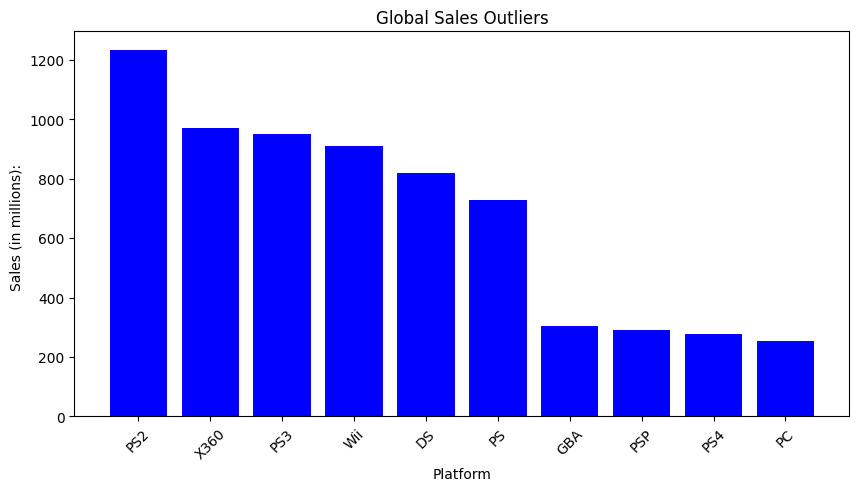

In [24]:
sales_by_platform = df.groupby("Platform")["Global_Sales"].sum().sort_values(ascending=False).head(10)
plt.figure(figsize=(10,5))
plt.bar(sales_by_platform.index, sales_by_platform.values, color="Blue")
plt.title("Global Sales Outliers")
plt.xlabel("Platform")
plt.ylabel("Sales (in millions): ")
plt.xticks(rotation=45)
plt.show()

In [25]:
df.describe(include='all')

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291,16291,16291.000000,16291,16291,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
unique,NaN,11325,31,NaN,12,576,NaN,NaN,NaN,NaN,NaN
top,NaN,Need for Speed: Most Wanted,DS,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN
freq,NaN,12,2131,NaN,3251,1339,NaN,NaN,NaN,NaN,NaN
mean,8290.190228,NaN,NaN,2006.405561,NaN,NaN,0.265647,0.147731,0.078833,0.048426,0.540910
std,4792.654450,NaN,NaN,5.832412,NaN,NaN,0.822432,0.509303,0.311879,0.190083,1.567345
min,1.000000,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4132.500000,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8292.000000,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12439.500000,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.040000,0.480000


## Histograms of dataset with boxplot indicating the outliers

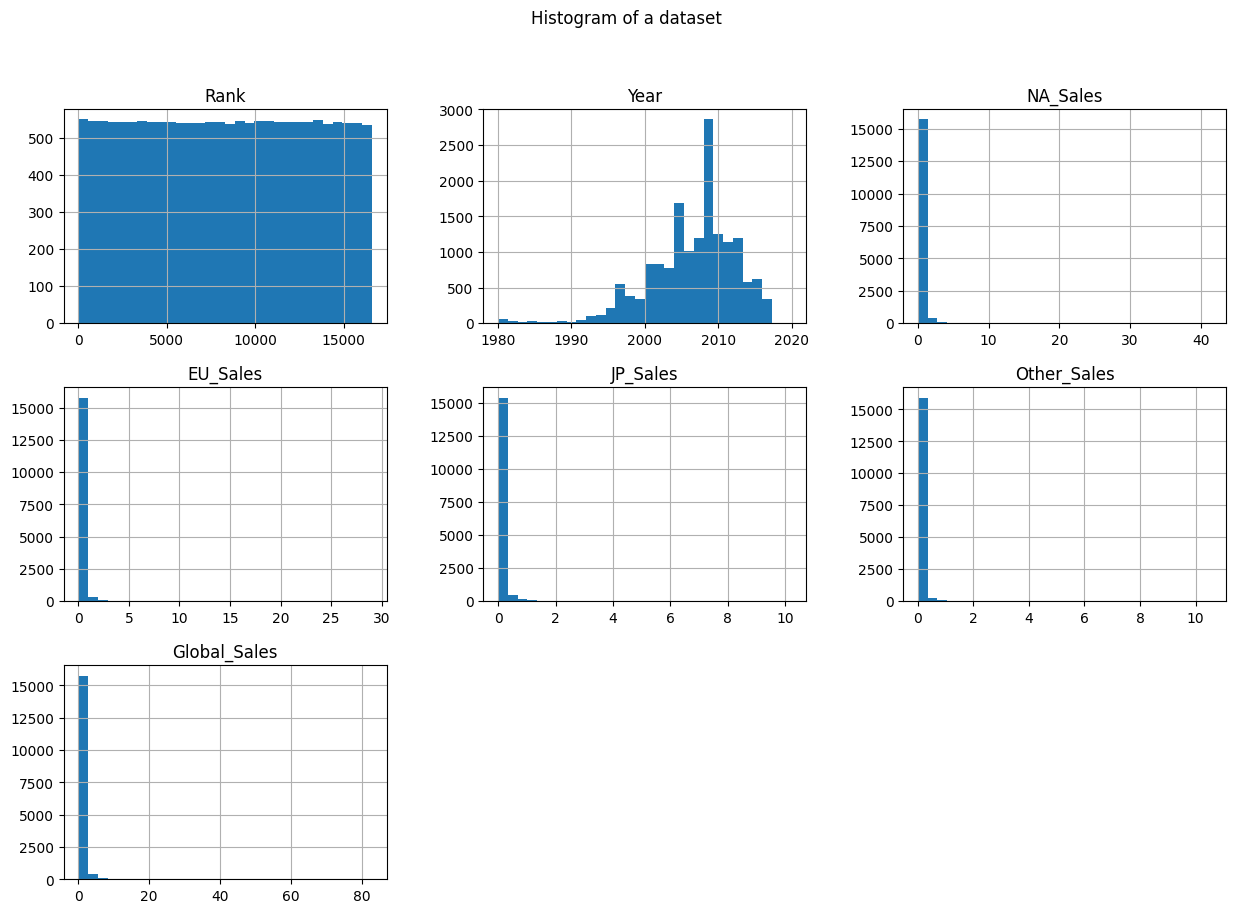

In [26]:
#histograms of all dataset
df.hist(bins = 30, figsize=(15,10))
plt.suptitle("Histogram of a dataset")
plt.show()

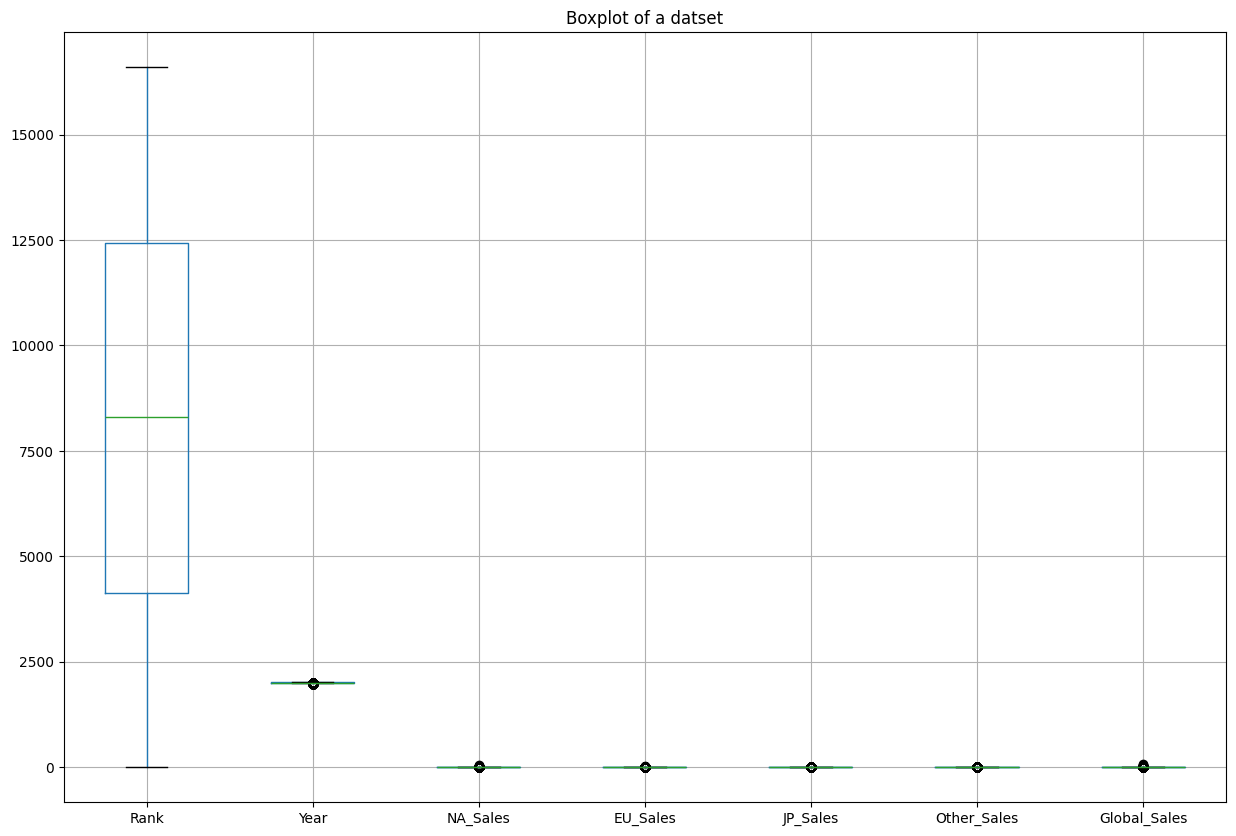

In [27]:
#boxplot of dataset showing outliers
df.boxplot(figsize=(15,10))
plt.title("Boxplot of a datset")
plt.show()

In [28]:
#checking for null values
df.isnull().sum()

Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

## Fix missing data

In [29]:
cat_cols = ['Name', 'Platform', 'Genre', 'Publisher']

for col in cat_cols:
    df[col] = df[col].fillna("Unknown")


In [30]:
#iterate through each categorial columns and fills/replace any missing values(nan) with unknown
num_cols = ['Year', 'NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales']

for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

In [31]:
#show head
df.head(16599)

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37
...,...,...,...,...,...,...,...,...,...,...,...
16286,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002.0,Platform,Kemco,0.01,0.00,0.00,0.00,0.01
16287,16597,Men in Black II: Alien Escape,GC,2003.0,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01
16288,16598,SCORE International Baja 1000: The Official Game,PS2,2008.0,Racing,Activision,0.00,0.00,0.00,0.00,0.01
16289,16599,Know How 2,DS,2010.0,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01


In [32]:
#checking for null values
df.describe(include='all')

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16291.000000,16291,16291,16291.000000,16291,16291,16291.000000,16291.000000,16291.000000,16291.000000,16291.000000
unique,NaN,11325,31,NaN,12,576,NaN,NaN,NaN,NaN,NaN
top,NaN,Need for Speed: Most Wanted,DS,NaN,Action,Electronic Arts,NaN,NaN,NaN,NaN,NaN
freq,NaN,12,2131,NaN,3251,1339,NaN,NaN,NaN,NaN,NaN
mean,8290.190228,NaN,NaN,2006.405561,NaN,NaN,0.265647,0.147731,0.078833,0.048426,0.540910
std,4792.654450,NaN,NaN,5.832412,NaN,NaN,0.822432,0.509303,0.311879,0.190083,1.567345
min,1.000000,NaN,NaN,1980.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4132.500000,NaN,NaN,2003.000000,NaN,NaN,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8292.000000,NaN,NaN,2007.000000,NaN,NaN,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12439.500000,NaN,NaN,2010.000000,NaN,NaN,0.240000,0.110000,0.040000,0.040000,0.480000


## Fixing outliers

In [33]:
#calculating iqr of the numeric values
numeric_cols = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales','Year']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\nColumn: {col}")
    print(f"Outliers count: {len(outliers)}")



Column: NA_Sales
Outliers count: 1658

Column: EU_Sales
Outliers count: 2053

Column: JP_Sales
Outliers count: 2407

Column: Other_Sales
Outliers count: 1645

Column: Global_Sales
Outliers count: 1826

Column: Year
Outliers count: 305


In [34]:
# FIX: clipping removed - it flattened the real hits (Wii Sports etc.) and altered Year values
# #fixing outliers of the described numerical columns
# for col in ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales','Year']:
#     Q1 = df[col].quantile(0.25)
#     Q3 = df[col].quantile(0.75)
#     IQR = Q3 - Q1
#     lower = Q1 - 1.5 * IQR
#     upper = Q3 + 1.5 * IQR
#
#     df[col] = df[col].clip(lower, upper)


In [35]:
#show head
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [36]:
#now again calculating iqr of the numeric values
numeric_cols = ['NA_Sales','EU_Sales','JP_Sales','Other_Sales','Global_Sales','Year']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\nColumn: {col}")
    print(f"Outliers count: {len(outliers)}")


Column: NA_Sales
Outliers count: 1658

Column: EU_Sales
Outliers count: 2053

Column: JP_Sales
Outliers count: 2407

Column: Other_Sales
Outliers count: 1645

Column: Global_Sales
Outliers count: 1826

Column: Year
Outliers count: 305


## Fixing catergorial inconsistencies

In [37]:
#showing unique categories to check categorial inconsistencies
print(df['Platform'].unique())
print(df['Genre'].unique())
print(df['Publisher'].unique()[:50])


['Wii' 'NES' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'SNES' 'GBA' '3DS' 'PS4' 'N64'
 'PS' 'XB' 'PC' '2600' 'PSP' 'XOne' 'GC' 'WiiU' 'GEN' 'DC' 'PSV' 'SAT'
 'SCD' 'WS' 'NG' 'TG16' '3DO' 'GG' 'PCFX']
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']
['Nintendo' 'Microsoft Game Studios' 'Take-Two Interactive'
 'Sony Computer Entertainment' 'Activision' 'Ubisoft' 'Bethesda Softworks'
 'Electronic Arts' 'Sega' 'SquareSoft' 'Atari' '505 Games' 'Capcom'
 'GT Interactive' 'Konami Digital Entertainment'
 'Sony Computer Entertainment Europe' 'Square Enix' 'LucasArts'
 'Virgin Interactive' 'Warner Bros. Interactive Entertainment'
 'Universal Interactive' 'Eidos Interactive' 'RedOctane' 'Vivendi Games'
 'Enix Corporation' 'Namco Bandai Games' 'Palcom' 'Hasbro Interactive'
 'THQ' 'Fox Interactive' 'Acclaim Entertainment' 'MTV Games'
 'Disney Interactive Studios' 'Majesco Entertainment' 'Codemasters'
 'Red Orb' 'Level 5' 'Arena Ente

In [38]:
#normalization of categories to lowercase so all becomes same
df['Publisher_lower'] = df['Publisher'].str.lower()
df['Platform_lower'] = df['Platform'].str.lower()
df['Genre_lower'] = df['Genre'].str.lower()

#.nunique() counts the number of distinct values in each column.
print("Publisher unique after lower():", df['Publisher_lower'].nunique())
print("Platform unique after lower():", df['Platform_lower'].nunique())
print("Genre unique after lower():", df['Genre_lower'].nunique())


Publisher unique after lower(): 576
Platform unique after lower(): 31
Genre unique after lower(): 12


In [39]:
#data cleaning loop
for col in cat_cols:
    df[col] = df[col].str.strip().str.lower().str.replace("-", " ").str.replace("_"," ")

In [40]:
#now again using unique to check categorial inconsistencies, normalization
print(df['Platform'].unique())
print(df['Genre'].unique())
print(df['Publisher'].unique()[:50])


['wii' 'nes' 'gb' 'ds' 'x360' 'ps3' 'ps2' 'snes' 'gba' '3ds' 'ps4' 'n64'
 'ps' 'xb' 'pc' '2600' 'psp' 'xone' 'gc' 'wiiu' 'gen' 'dc' 'psv' 'sat'
 'scd' 'ws' 'ng' 'tg16' '3do' 'gg' 'pcfx']
['sports' 'platform' 'racing' 'role playing' 'puzzle' 'misc' 'shooter'
 'simulation' 'action' 'fighting' 'adventure' 'strategy']
['nintendo' 'microsoft game studios' 'take two interactive'
 'sony computer entertainment' 'activision' 'ubisoft' 'bethesda softworks'
 'electronic arts' 'sega' 'squaresoft' 'atari' '505 games' 'capcom'
 'gt interactive' 'konami digital entertainment'
 'sony computer entertainment europe' 'square enix' 'lucasarts'
 'virgin interactive' 'warner bros. interactive entertainment'
 'universal interactive' 'eidos interactive' 'redoctane' 'vivendi games'
 'enix corporation' 'namco bandai games' 'palcom' 'hasbro interactive'
 'thq' 'fox interactive' 'acclaim entertainment' 'mtv games'
 'disney interactive studios' 'majesco entertainment' 'codemasters'
 'red orb' 'level 5' 'arena ente

## Fixing mismatch, invalid entries

In [41]:
#extracting/fixing all games(or rows) with no sales
zero_sales = df[
    (df['NA_Sales'] == 0) &
    (df['EU_Sales'] == 0) &
    (df['JP_Sales'] == 0) &
    (df['Other_Sales'] == 0) &
    (df['Global_Sales'] == 0)
]
zero_sales


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,Platform_lower,Genre_lower


In [42]:
# Validating Global Sales Consistency
df['Calculated_Global'] = df['NA_Sales'] + df['EU_Sales'] + df['JP_Sales'] + df['Other_Sales']

mismatch = df[df['Calculated_Global'].round(2) != df['Global_Sales'].round(2)]
mismatch
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,Platform_lower,Genre_lower,Calculated_Global
0,1,wii sports,wii,2006.0,sports,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,wii,sports,82.74
1,2,super mario bros.,nes,1985.0,platform,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,nes,platform,40.24
2,3,mario kart wii,wii,2008.0,racing,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,wii,racing,35.83
3,4,wii sports resort,wii,2009.0,sports,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,wii,sports,33.00
4,5,pokemon red/pokemon blue,gb,1996.0,role playing,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,gb,role-playing,31.38


## Fixing Duplicates

In [43]:
# Detecting and fixing Duplicate Rows in a DataFrame
df.duplicated().sum()
df[df.duplicated()]


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,Platform_lower,Genre_lower,Calculated_Global


In [44]:
# Handling fixing & dropping Duplicate Rows in a DataFrame
duplicate_names = df[df['Name'].duplicated()]
duplicate_names
df.drop_duplicates(inplace=True)
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,Platform_lower,Genre_lower,Calculated_Global
0,1,wii sports,wii,2006.0,sports,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,wii,sports,82.74
1,2,super mario bros.,nes,1985.0,platform,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,nes,platform,40.24
2,3,mario kart wii,wii,2008.0,racing,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,wii,racing,35.83
3,4,wii sports resort,wii,2009.0,sports,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,wii,sports,33.00
4,5,pokemon red/pokemon blue,gb,1996.0,role playing,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,gb,role-playing,31.38


## Checking histograms of dataset with boxplots incdicating outliers fixed above 

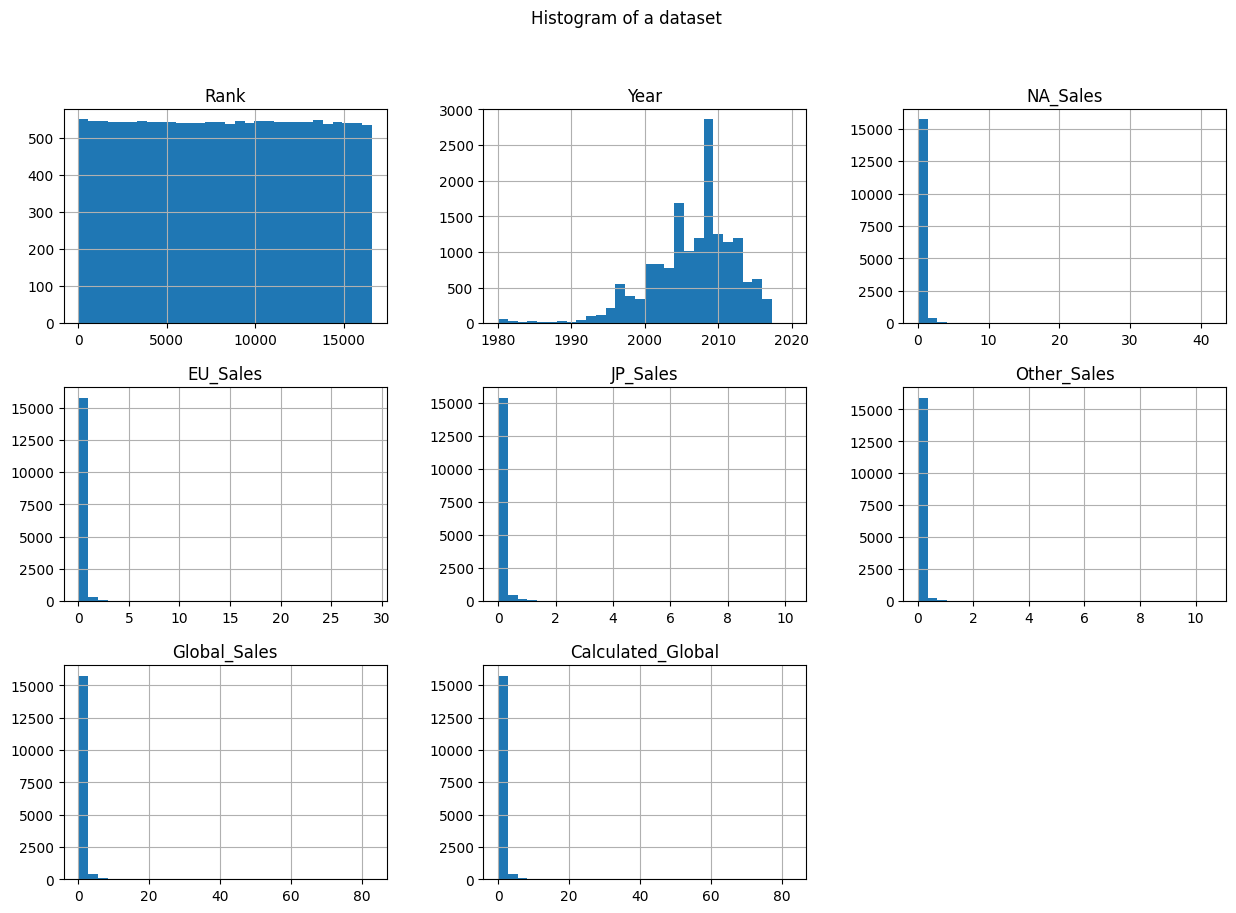

In [45]:
# checking fixed outliers using historgams
df.hist(bins = 30, figsize=(15,10))
plt.suptitle("Histogram of a dataset")
plt.show()

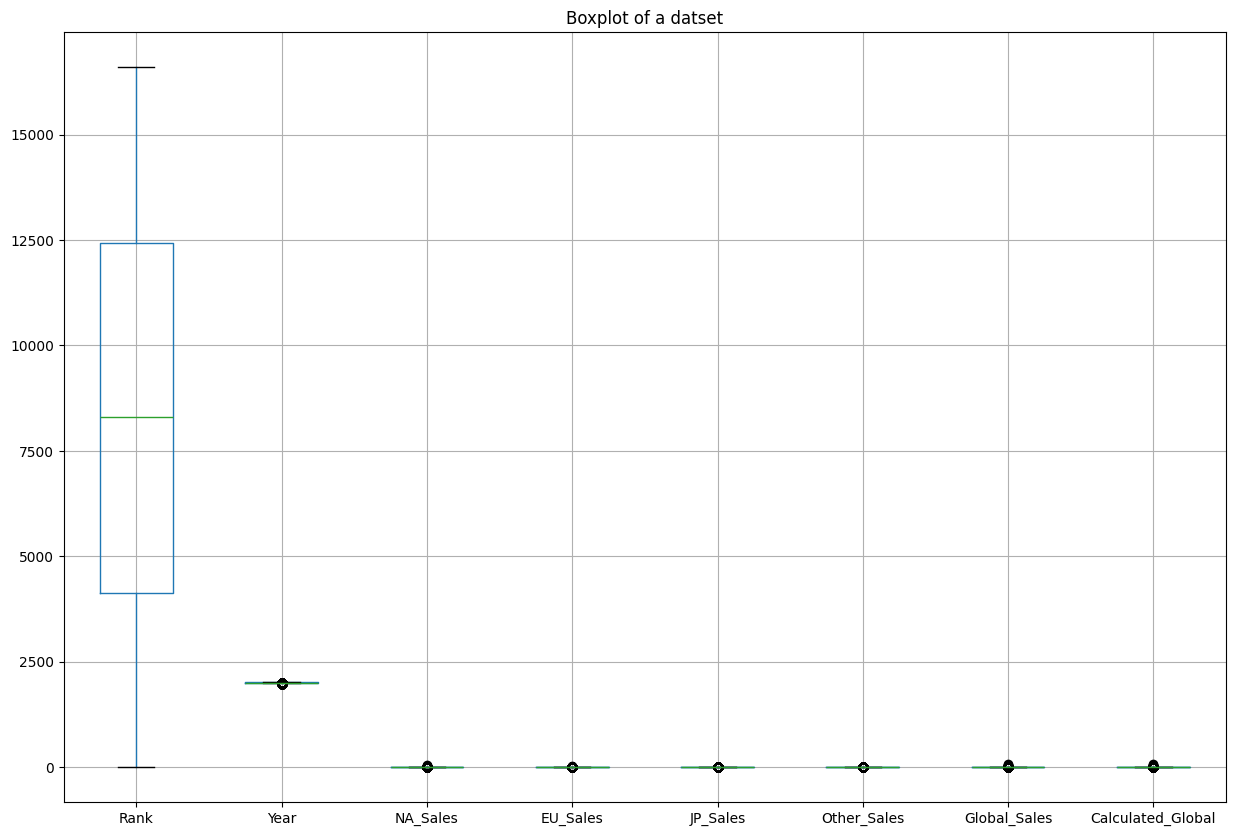

In [46]:
# checking fixed outliers using boxplot
df.boxplot(figsize=(15,10))
plt.title("Boxplot of a datset")
plt.show()

In [47]:
# FIX: clipping removed - it flattened the real hits
# # calculating iqr of 'calculated_global'
# for col in ['Calculated_Global']:
#     Q1 = df[col].quantile(0.25)
#     Q3 = df[col].quantile(0.75)
#     IQR = Q3 - Q1
#     lower = Q1 - 1.5 * IQR
#     upper = Q3 + 1.5 * IQR
#
#     df[col] = df[col].clip(lower, upper)


In [48]:
# fixing outliers of 'calculated_global'
numeric_cols = ['Calculated_Global']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5*IQR
    upper = Q3 + 1.5*IQR
    
    outliers = df[(df[col] < lower) | (df[col] > upper)]
    
    print(f"\nColumn: {col}")
    print(f"Outliers count: {len(outliers)}")


Column: Calculated_Global
Outliers count: 1821


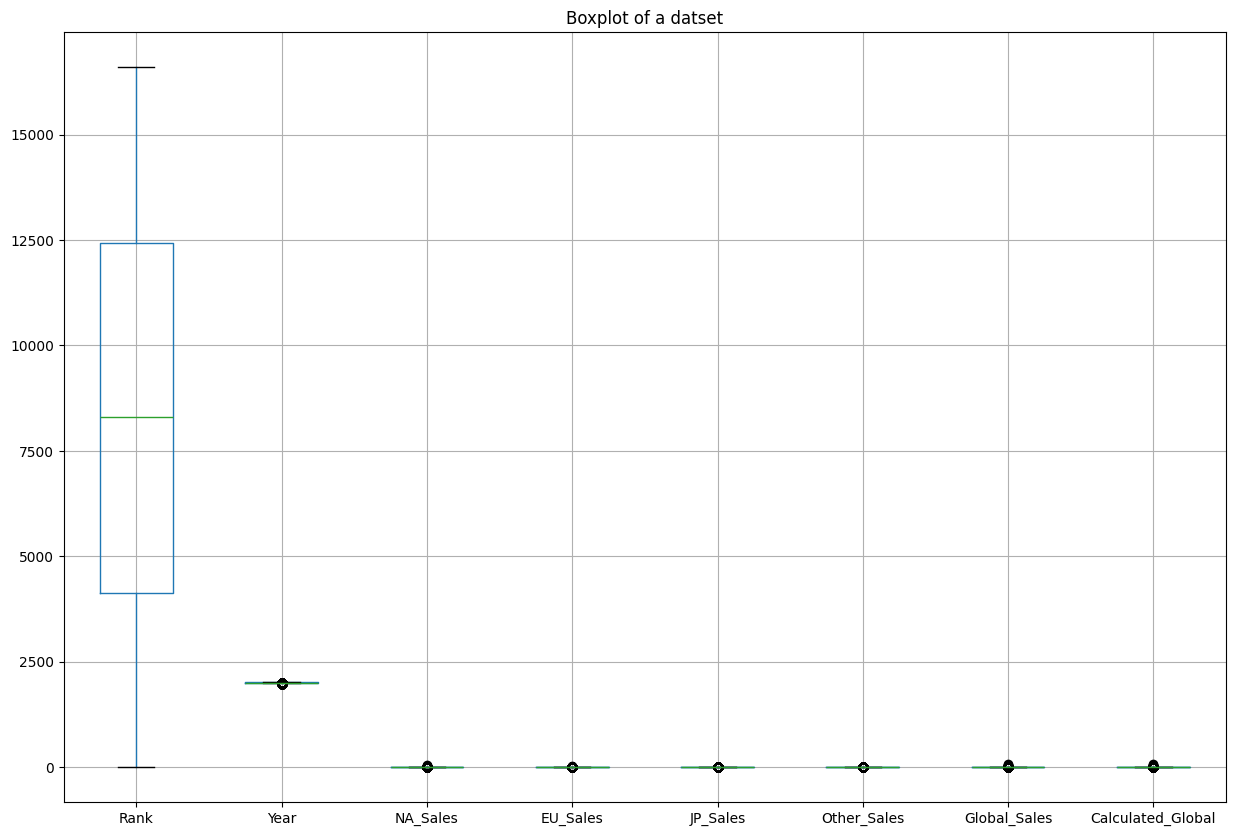

In [49]:
# now again check using boxplot
df.boxplot(figsize=(15,10))
plt.title("Boxplot of a datset")
plt.show()

### 🔍 Insights
- North America contributes the highest sales across most genres.
- A few games show extremely high global sales, indicating the presence of outliers.


## Publisher Grouping + Categorical Encoding Feature Engineering

In [50]:
# Grouping Publishers and Encoding Categorical Variables
publisher_counts = df['Publisher'].value_counts()
top10 = publisher_counts.index[:10]
df['Publisher_Grouped'] = df['Publisher'].apply(lambda x: x if x in top10 else 'Other_Publisher')
# one hot encoding of genre and platform
df = pd.get_dummies(df, columns=['Genre','Platform'], drop_first=True)
# calculated frequencies
freq = df['Publisher_Grouped'].value_counts()
df['Publisher_Freq'] = df['Publisher_Grouped'].map(freq)
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_scd,Platform_snes,Platform_tg16,Platform_wii,Platform_wiiu,Platform_ws,Platform_x360,Platform_xb,Platform_xone,Publisher_Freq
0,1,wii sports,2006.0,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,False,False,True,False,False,False,False,False,696
1,2,super mario bros.,1985.0,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,False,False,False,False,False,False,False,696
2,3,mario kart wii,2008.0,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,False,False,True,False,False,False,False,False,696
3,4,wii sports resort,2009.0,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,False,False,True,False,False,False,False,False,696
4,5,pokemon red/pokemon blue,1996.0,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,False,False,False,False,False,False,False,696


## Decade 

In [51]:
# creating new column decade from year
df['Decade'] = (df['Year']//10)*10
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_snes,Platform_tg16,Platform_wii,Platform_wiiu,Platform_ws,Platform_x360,Platform_xb,Platform_xone,Publisher_Freq,Decade
0,1,wii sports,2006.0,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,False,True,False,False,False,False,False,696,2000.0
1,2,super mario bros.,1985.0,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,False,False,False,False,False,False,696,1980.0
2,3,mario kart wii,2008.0,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,False,True,False,False,False,False,False,696,2000.0
3,4,wii sports resort,2009.0,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,False,True,False,False,False,False,False,696,2000.0
4,5,pokemon red/pokemon blue,1996.0,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,False,False,False,False,False,False,696,1990.0


## Game Age

In [52]:
# creating new column game age from year
df['Game_Age'] = 2025 - df['Year']
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_tg16,Platform_wii,Platform_wiiu,Platform_ws,Platform_x360,Platform_xb,Platform_xone,Publisher_Freq,Decade,Game_Age
0,1,wii sports,2006.0,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,True,False,False,False,False,False,696,2000.0,19.0
1,2,super mario bros.,1985.0,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,False,False,False,False,False,696,1980.0,40.0
2,3,mario kart wii,2008.0,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,True,False,False,False,False,False,696,2000.0,17.0
3,4,wii sports resort,2009.0,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,True,False,False,False,False,False,696,2000.0,16.0
4,5,pokemon red/pokemon blue,1996.0,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,False,False,False,False,False,696,1990.0,29.0


## Sales Ratios

In [53]:
# calculating ratios of all sales regions
df['NA_ratio'] = df['NA_Sales'] / df['Global_Sales']
df['EU_ratio'] = df['EU_Sales'] / df['Global_Sales']
df['JP_ratio'] = df['JP_Sales'] / df['Global_Sales']
df['OTHER_ratio'] = df['Other_Sales'] / df['Global_Sales']

In [54]:
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_x360,Platform_xb,Platform_xone,Publisher_Freq,Decade,Game_Age,NA_ratio,EU_ratio,JP_ratio,OTHER_ratio
0,1,wii sports,2006.0,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,False,False,696,2000.0,19.0,0.501450,0.350737,0.045564,0.102248
1,2,super mario bros.,1985.0,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,False,696,1980.0,40.0,0.722664,0.088966,0.169235,0.019135
2,3,mario kart wii,2008.0,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,False,False,696,2000.0,17.0,0.442490,0.359576,0.105807,0.092406
3,4,wii sports resort,2009.0,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,False,False,696,2000.0,16.0,0.477273,0.333636,0.099394,0.089697
4,5,pokemon red/pokemon blue,1996.0,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,False,696,1990.0,29.0,0.359260,0.283392,0.325789,0.031878


## Is Game a Hit?

In [55]:
# creating column to check if the game is a succes or not
df['Is_Hit'] = (df['Global_Sales']>1).astype(int)
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_xb,Platform_xone,Publisher_Freq,Decade,Game_Age,NA_ratio,EU_ratio,JP_ratio,OTHER_ratio,Is_Hit
0,1,wii sports,2006.0,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,False,696,2000.0,19.0,0.501450,0.350737,0.045564,0.102248,1
1,2,super mario bros.,1985.0,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,696,1980.0,40.0,0.722664,0.088966,0.169235,0.019135,1
2,3,mario kart wii,2008.0,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,False,696,2000.0,17.0,0.442490,0.359576,0.105807,0.092406,1
3,4,wii sports resort,2009.0,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,False,696,2000.0,16.0,0.477273,0.333636,0.099394,0.089697,1
4,5,pokemon red/pokemon blue,1996.0,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,696,1990.0,29.0,0.359260,0.283392,0.325789,0.031878,1


## Year, Decade, Game Age dtype change from float to int64

In [56]:
# changing dtype of year, decade, game age to int64
df['Year'] = df['Year'].round().astype('Int64')
df['Decade'] = df['Decade'].round().astype('Int64')
df['Game_Age'] = df['Game_Age'].round().astype('Int64')
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,Platform_xb,Platform_xone,Publisher_Freq,Decade,Game_Age,NA_ratio,EU_ratio,JP_ratio,OTHER_ratio,Is_Hit
0,1,wii sports,2006,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,False,False,696,2000,19,0.501450,0.350737,0.045564,0.102248,1
1,2,super mario bros.,1985,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,False,False,696,1980,40,0.722664,0.088966,0.169235,0.019135,1
2,3,mario kart wii,2008,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,False,False,696,2000,17,0.442490,0.359576,0.105807,0.092406,1
3,4,wii sports resort,2009,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,False,False,696,2000,16,0.477273,0.333636,0.099394,0.089697,1
4,5,pokemon red/pokemon blue,1996,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,False,False,696,1990,29,0.359260,0.283392,0.325789,0.031878,1


## Check null columns

In [57]:
# checking for any null columns
null_columns = df.columns[df.isnull().any()]
print(null_columns)

Index([], dtype='object')


## Publishers covered

In [58]:
# Flagging Major Publishers and Normalizing Publisher Names
df['Is_Nintendo'] = df['Publisher'].str.contains('nintendo')
df['Is_Sony_Entertainment'] = df['Publisher'].str.contains('sony computer entertainment|sony interactive entertainment')
df['Is_Sony'] = df['Publisher'].str.contains('sony')
df['Is_Electronic_Arts'] = df['Publisher'].str.contains(r'electronic arts|\bea\b')
df['Is_Namco'] = df['Publisher'].str.contains('namco')
df['Is_Konami'] = df['Publisher'].str.contains('konami')
df['Publisher'] = df['Publisher'].astype(str).str.lower()

In [59]:
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,EU_ratio,JP_ratio,OTHER_ratio,Is_Hit,Is_Nintendo,Is_Sony_Entertainment,Is_Sony,Is_Electronic_Arts,Is_Namco,Is_Konami
0,1,wii sports,2006,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,0.350737,0.045564,0.102248,1,True,False,False,False,False,False
1,2,super mario bros.,1985,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,0.088966,0.169235,0.019135,1,True,False,False,False,False,False
2,3,mario kart wii,2008,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,0.359576,0.105807,0.092406,1,True,False,False,False,False,False
3,4,wii sports resort,2009,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,0.333636,0.099394,0.089697,1,True,False,False,False,False,False
4,5,pokemon red/pokemon blue,1996,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,0.283392,0.325789,0.031878,1,True,False,False,False,False,False


In [60]:
print(df)

        Rank                                              Name  Year  \
0          1                                        wii sports  2006   
1          2                                 super mario bros.  1985   
2          3                                    mario kart wii  2008   
3          4                                 wii sports resort  2009   
4          5                          pokemon red/pokemon blue  1996   
...      ...                                               ...   ...   
16286  16596                woody woodpecker in crazy castle 5  2002   
16287  16597                     men in black ii: alien escape  2003   
16288  16598  score international baja 1000: the official game  2008   
16289  16599                                        know how 2  2010   
16290  16600                                  spirits & spells  2003   

        Publisher  NA_Sales  EU_Sales  JP_Sales  Other_Sales  Global_Sales  \
0        nintendo     41.49     29.02      3.77         8

# Feature Selection

## PCA

In [61]:
# importing libraries
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [62]:
#PCA on numeric features
#importing libraries
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import pandas as pd

num_cols = ["Year", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]

X_num = df[num_cols].dropna()
#standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_num)
#applying pca
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
#variance ratio
print("Explained Variance Ratio:", pca.explained_variance_ratio_)
#component loadings of each feature
component_names = [f"PC{i+1}" for i in range(pca.n_components_)]
pca_df = pd.DataFrame(pca.components_, columns=num_cols, index=component_names)
#print pca
print("\nPCA Component Loadings (with feature names):\n")
print(pca_df)


Explained Variance Ratio: [0.54024229 0.21638889]

PCA Component Loadings (with feature names):

         Year  NA_Sales  EU_Sales  JP_Sales  Other_Sales
PC1 -0.052486  0.541597  0.555913  0.377319     0.502503
PC2  0.891406 -0.005890  0.127745 -0.366755     0.233522


## F_Class If

In [63]:
# Feature Selection with SelectKBest (ANOVA F-test)
# F class if on year and sales values
#importing libraries
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

y = df["Publisher"]

X = df[["Year", "NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].dropna()
#applying kselect best
selector = SelectKBest(score_func=f_classif, k="all")
selector.fit(X, y)
#retrieve scores
scores = selector.scores_
for col, score in zip(X.columns, scores):
    print(f"{col}: {score}")


Year: 16.146444632170816
NA_Sales: 3.010973761941267
EU_Sales: 2.2071357347162497
JP_Sales: 8.127024751784635
Other_Sales: 1.3653376017371814


In [64]:
# 1. IMPORT LIBRARIES
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



## building preprocessing pipeline

In [65]:
#import libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identify column types
numeric_features = ['NA_Sales', 'EU_Sales', 'JP_Sales', 'Other_Sales']
categorical_features = ['Platform', 'Genre', 'Publisher']

# Create preprocessing steps
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


## preparing data for binary classification

In [66]:
# Remove missing values
df_ml = df.dropna()

# Features (X) and target (y)
X = df_ml.drop('Global_Sales', axis=1)

# Convert Global_Sales into binary classification
y = (df_ml['Global_Sales'] > df_ml['Global_Sales'].median()).astype(int)


In [67]:
numeric_features = []  # FIX: regional sales removed - they sum to Global_Sales (the target)
categorical_features = ['Publisher', 'Year']


## preprocessing with column transformer

In [68]:
#importing libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# Preprocessing with ColumnTransformer
preprocess = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)


In [69]:
from sklearn.model_selection import train_test_split
#splitting data into train and test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


## decision tree

In [70]:
#importing libraries
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
#decision tree classifier with preprocessing pipeline
#pipeline defining
dt_pipeline = Pipeline([
    ("preprocessing", preprocess),
    ("classifier", DecisionTreeClassifier(random_state=42))
])
#training model
dt_pipeline.fit(X_train, y_train)
dt_pred = dt_pipeline.predict(X_test)
#evaluate result of model
print("\n=== DECISION TREE ===")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print(confusion_matrix(y_test, dt_pred))
print(classification_report(y_test, dt_pred))



=== DECISION TREE ===
Accuracy: 0.6888616139920221
[[1098  556]
 [ 458 1147]]
              precision    recall  f1-score   support

           0       0.71      0.66      0.68      1654
           1       0.67      0.71      0.69      1605

    accuracy                           0.69      3259
   macro avg       0.69      0.69      0.69      3259
weighted avg       0.69      0.69      0.69      3259



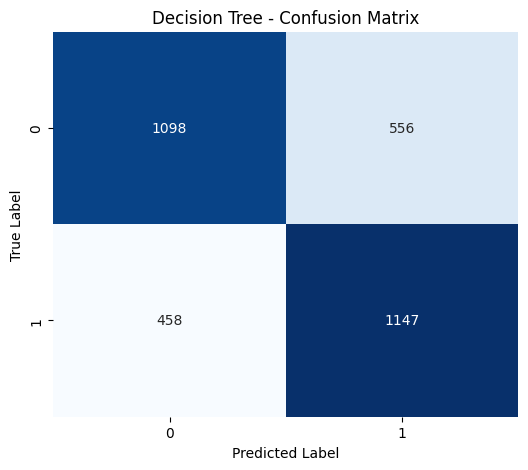

In [71]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, dt_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Decision Tree - Confusion Matrix")
plt.show()


In [72]:
df.head()

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,EU_ratio,JP_ratio,OTHER_ratio,Is_Hit,Is_Nintendo,Is_Sony_Entertainment,Is_Sony,Is_Electronic_Arts,Is_Namco,Is_Konami
0,1,wii sports,2006,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,0.350737,0.045564,0.102248,1,True,False,False,False,False,False
1,2,super mario bros.,1985,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,0.088966,0.169235,0.019135,1,True,False,False,False,False,False
2,3,mario kart wii,2008,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,0.359576,0.105807,0.092406,1,True,False,False,False,False,False
3,4,wii sports resort,2009,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,0.333636,0.099394,0.089697,1,True,False,False,False,False,False
4,5,pokemon red/pokemon blue,1996,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,0.283392,0.325789,0.031878,1,True,False,False,False,False,False


## logistic regression

In [73]:
from sklearn.linear_model import LogisticRegression
# Logistic Regression Classifier with Preprocessing Pipeline
#define pipeline
lr_model = Pipeline([
    ("preprocess", preprocess),
    ("model", LogisticRegression(max_iter=2000))
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Logistic Regression Accuracy:", accuracy_score(y_test, lr_pred))


Logistic Regression Accuracy: 0.6922368824792882


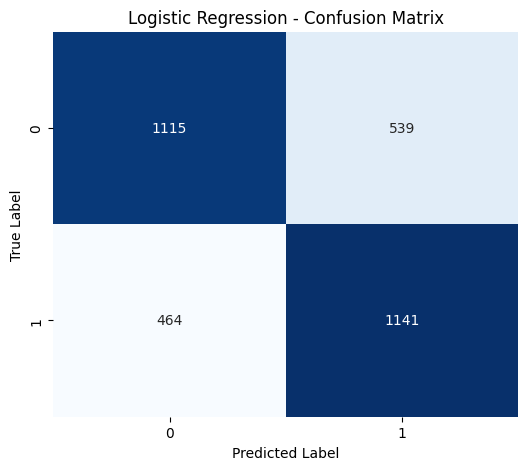

In [74]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, lr_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Logistic Regression - Confusion Matrix")
plt.show()


## KNN

In [75]:
from sklearn.neighbors import KNeighborsClassifier
# KNN Classifier with Preprocessing Pipeline
#define pipeline
knn_model = Pipeline([
    ("preprocess", preprocess),
    ("model", KNeighborsClassifier())
])
#train, test
knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)
#evaluate model
print("KNN Accuracy:", accuracy_score(y_test, knn_pred))


KNN Accuracy: 0.6403804848112918


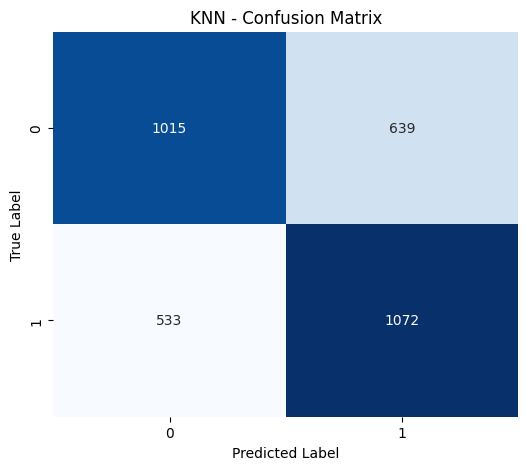

In [76]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, knn_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("KNN - Confusion Matrix")
plt.show()


## Random forest

In [77]:
from sklearn.ensemble import RandomForestClassifier
#randomforest classifier with preprocessing pipeline
#define pipeline
rf_model = Pipeline([
    ("preprocess", preprocess),
    ("model", RandomForestClassifier(random_state=42))
])
#train, test
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
#evaluate model
print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))


Random Forest Accuracy: 0.6888616139920221


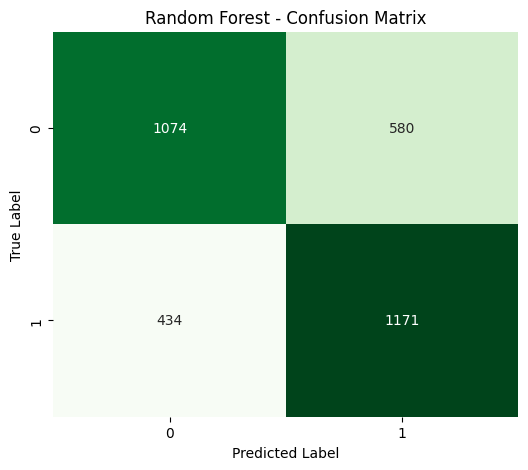

In [78]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, rf_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Random Forest - Confusion Matrix")
plt.show()


In [79]:
df.head(10)

,Rank,Name,Year,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Publisher_lower,...,EU_ratio,JP_ratio,OTHER_ratio,Is_Hit,Is_Nintendo,Is_Sony_Entertainment,Is_Sony,Is_Electronic_Arts,Is_Namco,Is_Konami
0,1,wii sports,2006,nintendo,41.49,29.02,3.77,8.46,82.74,nintendo,...,0.350737,0.045564,0.102248,1,True,False,False,False,False,False
1,2,super mario bros.,1985,nintendo,29.08,3.58,6.81,0.77,40.24,nintendo,...,0.088966,0.169235,0.019135,1,True,False,False,False,False,False
2,3,mario kart wii,2008,nintendo,15.85,12.88,3.79,3.31,35.82,nintendo,...,0.359576,0.105807,0.092406,1,True,False,False,False,False,False
3,4,wii sports resort,2009,nintendo,15.75,11.01,3.28,2.96,33.00,nintendo,...,0.333636,0.099394,0.089697,1,True,False,False,False,False,False
4,5,pokemon red/pokemon blue,1996,nintendo,11.27,8.89,10.22,1.00,31.37,nintendo,...,0.283392,0.325789,0.031878,1,True,False,False,False,False,False
5,6,tetris,1989,nintendo,23.20,2.26,4.22,0.58,30.26,nintendo,...,0.074686,0.139458,0.019167,1,True,False,False,False,False,False
6,7,new super mario bros.,2006,nintendo,11.38,9.23,6.50,2.90,30.01,nintendo,...,0.307564,0.216594,0.096634,1,True,False,False,False,False,False
7,8,wii play,2006,nintendo,14.03,9.20,2.93,2.85,29.02,nintendo,...,0.317023,0.100965,0.098208,1,True,False,False,False,False,False
8,9,new super mario bros. wii,2009,nintendo,14.59,7.06,4.70,2.26,28.62,nintendo,...,0.246681,0.164221,0.078966,1,True,False,False,False,False,False
9,10,duck hunt,1984,nintendo,26.93,0.63,0.28,0.47,28.31,nintendo,...,0.022254,0.009890,0.016602,1,True,False,False,False,False,False


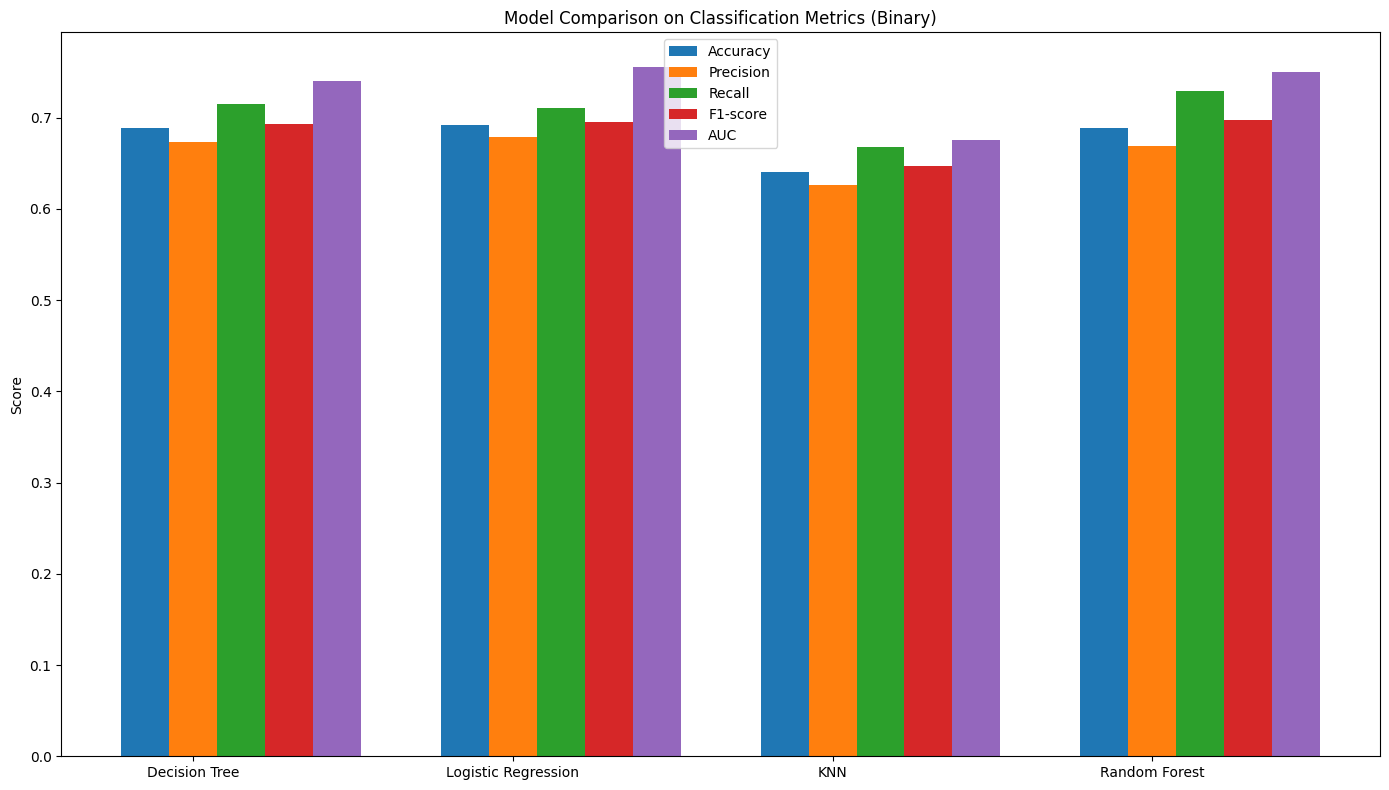

In [80]:
#model comparison of metrics ()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import matplotlib.pyplot as plt
import numpy as np

def compute_auc(model, X_test, y_test):
    proba = model.predict_proba(X_test)
    # binary classification → use only class 1 column
    if proba.shape[1] == 2:
        return roc_auc_score(y_test, proba[:, 1])
    else:
        return np.nan  # for models without proper probabilities
# All metrics defined here
# Their accuracy, precision, recall, f1-score, auc
metrics = {
    "Decision Tree": {
        "Accuracy": accuracy_score(y_test, dt_pred),
        "Precision": precision_score(y_test, dt_pred, average="binary"),
        "Recall": recall_score(y_test, dt_pred, average="binary"),
        "F1-score": f1_score(y_test, dt_pred, average="binary"),
        "AUC": compute_auc(dt_pipeline, X_test, y_test)
    },
    "Logistic Regression": {
        "Accuracy": accuracy_score(y_test, lr_pred),
        "Precision": precision_score(y_test, lr_pred, average="binary"),
        "Recall": recall_score(y_test, lr_pred, average="binary"),
        "F1-score": f1_score(y_test, lr_pred, average="binary"),
        "AUC": compute_auc(lr_model, X_test, y_test)
    },
    "KNN": {
        "Accuracy": accuracy_score(y_test, knn_pred),
        "Precision": precision_score(y_test, knn_pred, average="binary"),
        "Recall": recall_score(y_test, knn_pred, average="binary"),
        "F1-score": f1_score(y_test, knn_pred, average="binary"),
        "AUC": compute_auc(knn_model, X_test, y_test)
    },
    "Random Forest": {
        "Accuracy": accuracy_score(y_test, rf_pred),
        "Precision": precision_score(y_test, rf_pred, average="binary"),
        "Recall": recall_score(y_test, rf_pred, average="binary"),
        "F1-score": f1_score(y_test, rf_pred, average="binary"),
        "AUC": compute_auc(rf_model, X_test, y_test)
    }
}

# Preparing Data
models = list(metrics.keys())
metric_names = list(metrics["Decision Tree"].keys())
values = np.array([[metrics[m][metric] for metric in metric_names] for m in models])

# Plotting bar graph
x = np.arange(len(models))
width = 0.15

plt.figure(figsize=(14, 8))

for i, metric in enumerate(metric_names):
    plt.bar(x + i * width, values[:, i], width, label=metric)

plt.xticks(x + width, models)
plt.ylabel("Score")
plt.title("Model Comparison on Classification Metrics (Binary)")
plt.legend()
plt.tight_layout()
plt.show()


Accuracy: 0.8597729364835839
              precision    recall  f1-score   support

        High       0.00      0.00      0.00        12
         Low       0.90      0.95      0.92      2853
      Medium       0.39      0.25      0.30       394

    accuracy                           0.86      3259
   macro avg       0.43      0.40      0.41      3259
weighted avg       0.84      0.86      0.85      3259


Feature Importance:

     Feature  Importance
3       Year    0.328538
2  Publisher    0.301087
1      Genre    0.231775
0   Platform    0.138601


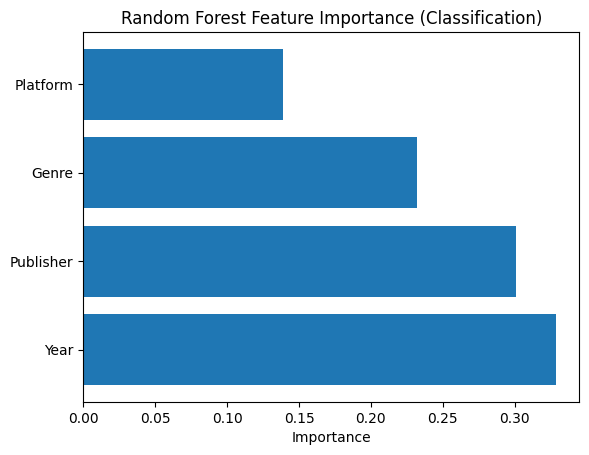

In [81]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

# 1. Load Dataset
df = pd.read_csv("vgsales.csv")   # keep CSV in same folder

# 2. Create Classes (Target)
df["Sales_Class"] = pd.cut(
    df["Global_Sales"],
    bins=[-1, 1, 10, df["Global_Sales"].max()],
    labels=["Low", "Medium", "High"]
)

# Drop missing values
df = df.dropna(subset=["Sales_Class", "Platform", "Genre", "Publisher", "Year"])

# 3. Features & Target
X = df[["Platform", "Genre", "Publisher", "Year"]].copy()
y = df["Sales_Class"]

# 4. Encode Categorical Data
for col in ["Platform", "Genre", "Publisher"]:
    le = LabelEncoder()
    X[col] = le.fit_transform(X[col])

# 5. Train Random Forest CLASSIFIER
rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

X_tr_cls, X_te_cls, y_tr_cls, y_te_cls = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
rf.fit(X_tr_cls, y_tr_cls)
rf_pred_cls = rf.predict(X_te_cls)
print("Accuracy:", accuracy_score(y_te_cls, rf_pred_cls))
print(classification_report(y_te_cls, rf_pred_cls))

# 6. Feature Importance
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("\nFeature Importance:\n")
print(importance)

# 7. Plot Feature Importance
plt.figure()
plt.barh(importance["Feature"], importance["Importance"])
plt.xlabel("Importance")
plt.title("Random Forest Feature Importance (Classification)")
plt.show()


In [82]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report


In [83]:
ann_model = Pipeline(steps=[
    ('preprocessor', preprocess),
    ('scaler', StandardScaler(with_mean=False)),
    ('ann', MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation='relu',
        solver='adam',
        max_iter=500,
        random_state=42
    ))
])


In [84]:
ann_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform